# Ridge Regression — Development and Validation Evaluation

## 1. Project context

This notebook documents the existing Ridge Regression validation experiment
for Lloyds Banking Group (`LLOY.L`), listed on the London Stock Exchange.

Yahoo Finance is the project's designated market-data source. This notebook
loads previously generated evaluation artefacts; it does not download market
data, retrain models or rerun statistical tests.

## 2. Experimental design

The target is the forward return defined as:

`R(t, h) = Close(t + h) / Open(t + 1) - 1`

The forecast horizons are 1, 5 and 10 trading sessions. The evaluation uses
the previously stored expanding-window validation results.

The development period is 24 October 2016 to 20 October 2023. The validation
period is 23 October 2023 to 22 October 2025.

The Final Test period, 23 October 2025 to 23 October 2026, is reserved and
must not be accessed during this evaluation.

## 3. Evaluation objectives

- Inspect the stored Ridge Regression metrics.
- Compare performance across forecast horizons.
- Visualise the existing validation metrics.
- Review existing baseline comparisons and statistical-test results.
- Document limitations without claiming that forecasting performance
  establishes trading profitability.


## 4. Load existing evaluation artefacts

In [1]:
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the project root independently of the notebook working directory.
working_directory = Path.cwd().resolve()

ROOT = next(
    (
        candidate
        for candidate in (working_directory, *working_directory.parents)
        if (candidate / "reports").is_dir()
        and (candidate / "src").is_dir()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root containing reports and src."
    )

ARTEFACT_DIR = (
    ROOT / "reports" / "model_evaluation" / "LLOY.L" / "ridge_regression"
)

METRICS_PATH = ARTEFACT_DIR / "ridge_validation_metrics.csv"
PREDICTIONS_PATH = ARTEFACT_DIR / "ridge_validation_predictions.csv"
BASELINE_METRICS_PATH = ARTEFACT_DIR / "ridge_baseline_comparison_metrics.csv"
ALIGNED_PREDICTIONS_PATH = ARTEFACT_DIR / "ridge_baseline_aligned_predictions.csv"
STATISTICAL_TESTS_PATH = ARTEFACT_DIR / "ridge_paired_statistical_tests.csv"
RUN_METADATA_PATH = ARTEFACT_DIR / "ridge_validation_run.json"

required_paths = [
    METRICS_PATH,
    PREDICTIONS_PATH,
    BASELINE_METRICS_PATH,
    ALIGNED_PREDICTIONS_PATH,
    STATISTICAL_TESTS_PATH,
    RUN_METADATA_PATH,
]

for path in required_paths:
    if not path.is_file():
        raise FileNotFoundError(f"Required artefact not found: {path}")

metrics = pd.read_csv(METRICS_PATH)
predictions = pd.read_csv(PREDICTIONS_PATH)
baseline_metrics = pd.read_csv(BASELINE_METRICS_PATH)
aligned_predictions = pd.read_csv(ALIGNED_PREDICTIONS_PATH)
statistical_tests = pd.read_csv(STATISTICAL_TESTS_PATH)

run_metadata = json.loads(RUN_METADATA_PATH.read_text(encoding="utf-8"))

print(f"Project root: {ROOT}")
print(f"Ridge validation metric rows: {len(metrics):,}")
print(f"Ridge validation prediction rows: {len(predictions):,}")
print(f"Baseline comparison rows: {len(baseline_metrics):,}")
print(f"Aligned prediction rows: {len(aligned_predictions):,}")
print(f"Stored statistical-test rows: {len(statistical_tests):,}")

print("\nValidation metric columns:")
print(metrics.columns.tolist())

print("\nStored run metadata:")
print(json.dumps(run_metadata, indent=2, ensure_ascii=False))


Project root: /home/anderjcruz/projects/Quantitative-Trading
Ridge validation metric rows: 3
Ridge validation prediction rows: 1,505
Baseline comparison rows: 12
Aligned prediction rows: 4,515
Stored statistical-test rows: 18

Validation metric columns:
['horizon', 'model', 'sample_size', 'mae', 'rmse', 'directional_accuracy', 'spearman_correlation', 'r_squared']

Stored run metadata:
{
  "ticker": "LLOY.L",
  "model": "ridge_regression",
  "alpha": 1.0,
  "horizons": [
    1,
    5,
    10
  ],
  "development_start": "2016-10-24",
  "development_end": "2023-10-20",
  "validation_start": "2023-10-23",
  "validation_end": "2025-10-22",
  "last_loaded_session": "2025-10-22",
  "historical_observations": 2731,
  "minimum_training_samples": 500,
  "prediction_count": 1505,
  "final_test_used": false,
  "backtesting_performed": false,
  "predictions_file": "ridge_validation_predictions.csv",
  "metrics_file": "ridge_validation_metrics.csv"
}


## 5. Ridge Regression validation metrics

In [2]:
display(metrics.sort_values("horizon").reset_index(drop=True))

print("\nMetrics by forecast horizon:")
for horizon, group in metrics.groupby("horizon", sort=True):
    print(f"\nHorizon: {horizon} trading session(s)")
    display(group.reset_index(drop=True))


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
0,1,ridge_regression,506,0.009777,0.013688,0.505929,0.040177,-0.010919
1,5,ridge_regression,502,0.026023,0.035465,0.597610,0.178884,-0.016138
2,10,ridge_regression,497,0.039124,0.051289,0.561368,0.123284,-0.057729



Metrics by forecast horizon:

Horizon: 1 trading session(s)


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
0,1,ridge_regression,506,0.009777,0.013688,0.505929,0.040177,-0.010919



Horizon: 5 trading session(s)


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
0,5,ridge_regression,502,0.026023,0.035465,0.59761,0.178884,-0.016138



Horizon: 10 trading session(s)


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
0,10,ridge_regression,497,0.039124,0.051289,0.561368,0.123284,-0.057729


## 6. Visual analysis of validation performance

In [ ]:
# Plot MAE by forecast horizon using stored validation metrics.
if {"horizon", "model", "mae"}.issubset(metrics.columns):
    mae_data = metrics.pivot(
        index="horizon", columns="model", values="mae"
    ).sort_index()

    ax = mae_data.plot(
        kind="bar",
        figsize=(9, 5),
        title="Ridge Regression — Validation MAE by Forecast Horizon",
    )
    ax.set_xlabel("Forecast horizon (trading sessions)")
    ax.set_ylabel("Mean Absolute Error")
    ax.legend(title="Model")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("The required MAE columns are unavailable.")


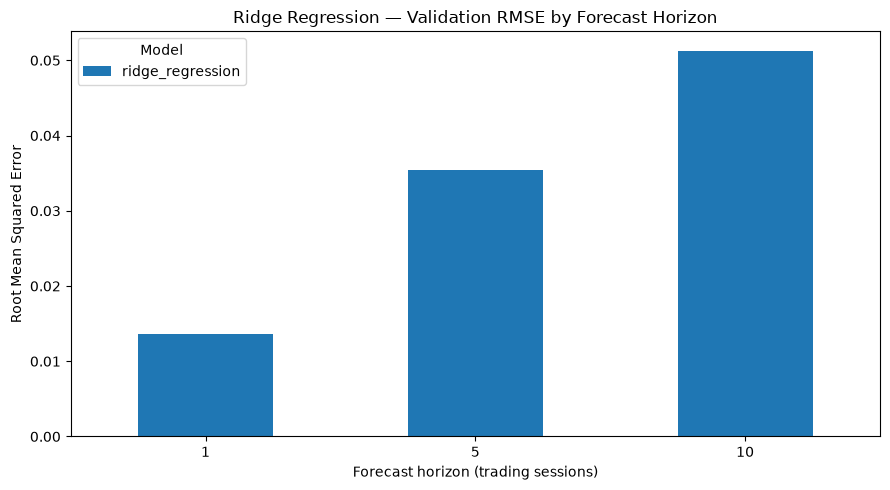

In [3]:
# Plot RMSE by forecast horizon using stored validation metrics.
if {"horizon", "model", "rmse"}.issubset(metrics.columns):
    rmse_data = metrics.pivot(
        index="horizon", columns="model", values="rmse"
    ).sort_index()

    ax = rmse_data.plot(
        kind="bar",
        figsize=(9, 5),
        title="Ridge Regression — Validation RMSE by Forecast Horizon",
    )
    ax.set_xlabel("Forecast horizon (trading sessions)")
    ax.set_ylabel("Root Mean Squared Error")
    ax.legend(title="Model")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("The required RMSE columns are unavailable.")


## 7. Existing baseline comparisons

In [4]:
print("Stored baseline comparison metrics:")
display(baseline_metrics)

print("\nBaseline comparison columns:")
print(baseline_metrics.columns.tolist())


Stored baseline comparison metrics:


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
0,1,ridge_regression,506,0.009777,0.013688,0.505929,0.040177,-0.010919
1,1,zero_return,506,0.009757,0.013655,0.470356,NaN,-0.006043
2,1,historical_mean,506,0.009759,0.013659,0.498024,-0.097032,-0.006630
3,1,historical_median,506,0.009793,0.013693,0.470356,-0.093345,-0.011557
4,5,ridge_regression,502,0.026023,0.035465,0.597610,0.178884,-0.016138
5,5,zero_return,502,0.026485,0.035934,0.386454,NaN,-0.043174
6,5,historical_mean,502,0.026355,0.035839,0.583665,-0.135498,-0.037668
7,5,historical_median,502,0.026620,0.036050,0.436255,-0.126595,-0.049921
8,10,ridge_regression,497,0.039124,0.051289,0.561368,0.123284,-0.057729
9,10,zero_return,497,0.039843,0.052158,0.350101,NaN,-0.093884



Baseline comparison columns:
['horizon', 'model', 'sample_size', 'mae', 'rmse', 'directional_accuracy', 'spearman_correlation', 'r_squared']


In [ ]:
print("Stored aligned predictions:")
display(aligned_predictions.head(10))

print("\nPrediction counts by horizon and model:")
if {"horizon", "model"}.issubset(aligned_predictions.columns):
    display(
        aligned_predictions.groupby(["horizon", "model"])
        .size()
        .rename("row_count")
        .reset_index()
    )
else:
    print("The expected horizon/model columns are unavailable.")


## 8. Existing paired statistical-test results

In [5]:
print("Stored Ridge-related statistical-test results:")
display(statistical_tests)

print("\nStatistical-test columns:")
print(statistical_tests.columns.tolist())

significance_column = "significant_after_holm_5pct"

if significance_column in statistical_tests.columns:
    values = (
        statistical_tests[significance_column]
        .astype(str)
        .str.strip()
        .str.lower()
    )
    significant = values.isin({"true", "1", "yes"})
    print(
        "Comparisons marked significant after Holm correction: "
        f"{int(significant.sum())} / {len(statistical_tests)}"
    )
else:
    print(
        "No recognised Holm-adjusted significance column was found. "
        "Inspect the stored results before interpreting statistical significance."
    )


Stored Ridge-related statistical-test results:


,horizon,loss,model_a,model_b,sample_size,mean_loss_difference_ridge_minus_baseline,hac_lag,hac_long_run_variance,hac_standard_error,hac_z_statistic,hac_p_value,bootstrap_block_length,bootstrap_repetitions,bootstrap_ci_95_lower,bootstrap_ci_95_upper,holm_adjusted_p_value,significant_after_holm_5pct
0,1,absolute,ridge_regression,zero_return,506,1.993501e-05,10,9.442858e-07,0.000043,0.461466,0.644464,10,5000,-0.000063,1.079915e-04,1.000000,False
1,1,squared,ridge_regression,zero_return,506,9.037462e-07,10,6.997830e-10,0.000001,0.768493,0.442194,10,5000,-0.000001,3.243043e-06,1.000000,False
2,1,absolute,ridge_regression,historical_mean,506,1.801000e-05,10,9.658327e-07,0.000044,0.412229,0.680172,10,5000,-0.000064,1.047166e-04,1.000000,False
3,1,squared,ridge_regression,historical_mean,506,7.950587e-07,10,6.992175e-10,0.000001,0.676345,0.498822,10,5000,-0.000002,3.128419e-06,1.000000,False
4,1,absolute,ridge_regression,historical_median,506,-1.624198e-05,10,8.030182e-07,0.000040,-0.407710,0.683486,10,5000,-0.000094,6.244030e-05,1.000000,False
5,1,squared,ridge_regression,historical_median,506,-1.181989e-07,10,5.692077e-10,0.000001,-0.111443,0.911265,10,5000,-0.000002,1.979051e-06,1.000000,False
6,5,absolute,ridge_regression,zero_return,502,-4.615849e-04,10,2.489474e-05,0.000223,-2.072763,0.038194,10,5000,-0.000892,-4.855660e-05,0.534721,False
7,5,squared,ridge_regression,zero_return,502,-3.346508e-05,10,1.609696e-07,0.000018,-1.868839,0.061645,10,5000,-0.000070,1.760224e-07,0.678098,False
8,5,absolute,ridge_regression,historical_mean,502,-3.319815e-04,10,2.428073e-05,0.000220,-1.509506,0.131170,10,5000,-0.000773,8.292887e-05,1.000000,False
9,5,squared,ridge_regression,historical_mean,502,-2.664929e-05,10,1.552238e-07,0.000018,-1.515509,0.129644,10,5000,-0.000064,6.289086e-06,1.000000,False



Statistical-test columns:
['horizon', 'loss', 'model_a', 'model_b', 'sample_size', 'mean_loss_difference_ridge_minus_baseline', 'hac_lag', 'hac_long_run_variance', 'hac_standard_error', 'hac_z_statistic', 'hac_p_value', 'bootstrap_block_length', 'bootstrap_repetitions', 'bootstrap_ci_95_lower', 'bootstrap_ci_95_upper', 'holm_adjusted_p_value', 'significant_after_holm_5pct']
Comparisons marked significant after Holm correction: 0 / 18


## 9. Interpretation and limitations

The stored Ridge Regression validation metrics show how prediction errors and
directional measures vary across the 1-, 5- and 10-session horizons.

Negative out-of-sample R² values indicate that the model did not outperform
the zero-centred squared-error reference implied by that metric. They do not,
by themselves, establish whether Ridge outperforms every baseline; that
question must be assessed using the stored baseline comparison results.

Directional accuracy and rank correlation are descriptive measures. They do
not establish profitability, account for transaction costs or slippage, or
constitute evidence that a trading strategy is suitable for deployment.

Statistical conclusions must be based on the stored comparisons and their
reported multiple-testing correction. This notebook does not rerun those
tests.

## 10. Experiment status

- Existing Ridge validation artefacts are loaded from disk.
- No model training is performed.
- No statistical tests are rerun.
- No backtesting is performed.
- The Final Test remains reserved and is not accessed.
- This notebook documents forecasting evaluation only; it does not authorise
  trading signals or live trading.
